In [ ]:
# Explore the product listing dynamics on Amazon UK to extract actionable business insights

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

In [3]:
df = pd.read_csv("/home/diego/Downloads/amz_uk_price_prediction_dataset.csv")

In [4]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [5]:
df.shape #rows and columns

(2443651, 9)

In [7]:
df.dtypes

uid                    int64
asin                     str
title                    str
stars                float64
reviews                int64
price                float64
isBestSeller            bool
boughtInLastMonth      int64
category                 str
dtype: object

In [8]:
df.isnull().sum().sort_values(ascending=False) #No null values

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

In [16]:
#Frequency table - category
frequency_table = df["category"].value_counts()

In [17]:
#Proportion of each unique value in the category
proportion_table = df["category"].value_counts(normalize=True)

frequency_table, proportion_table

(category
 Sports & Outdoors                         836265
 Beauty                                     19312
 Handmade Clothing, Shoes & Accessories     19229
 Bath & Body                                19092
 Birthday Gifts                             18978
                                            ...  
 Motorbike Chassis                            107
 Alexa Built-In Devices                       107
 Plugs                                        107
 Smart Home Security & Lighting               104
 Smart Speakers                                54
 Name: count, Length: 296, dtype: int64,
 category
 Sports & Outdoors                         0.342219
 Beauty                                    0.007903
 Handmade Clothing, Shoes & Accessories    0.007869
 Bath & Body                               0.007813
 Birthday Gifts                            0.007766
                                             ...   
 Motorbike Chassis                         0.000044
 Alexa Built-In Devices  

In [20]:
top_five = frequency_table.head(5)             
top_five

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

<Axes: xlabel='category'>

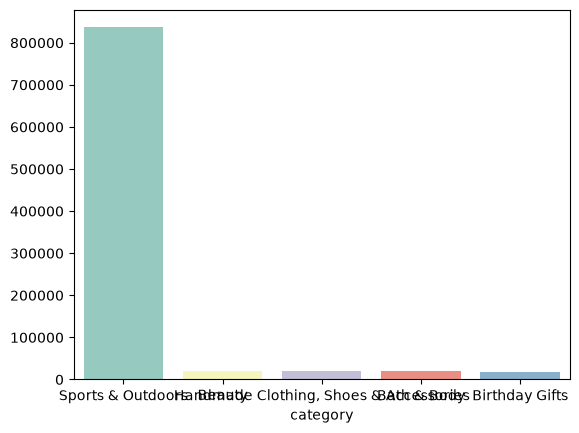

In [26]:
# Plotting a bar chart using SEABORN the 'count' values from top_five', with colors sourced from the "Set3" palette
sns.barplot(x=top_five.index, y=top_five.values, hue=top_five.index, palette="Set3", legend=False) #y=top_five.values without [count] because is a Pandas Series

In [ ]:
#In seaborn, hue means “which variable decides the color?” 
#You give it a column (or a list of values), and seaborn gives each unique value its own color.

<Axes: ylabel='category'>

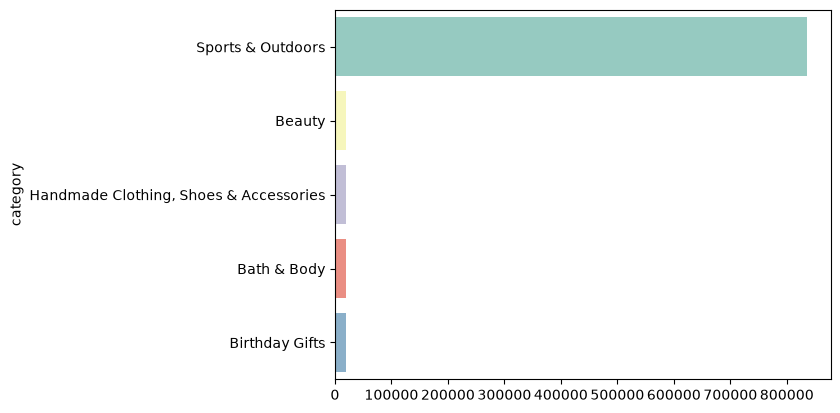

In [28]:
sns.barplot(x=top_five.values, y=top_five.index, hue=top_five.index, palette="Set3", legend=False)

<Axes: >

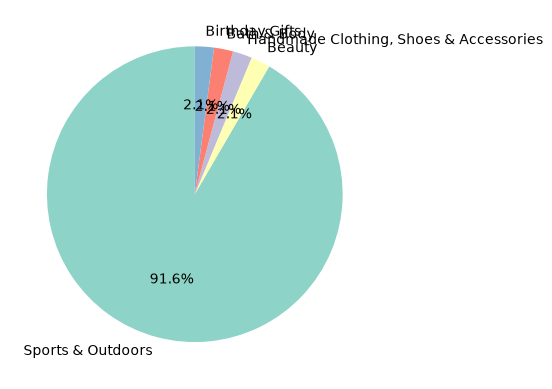

In [30]:
# Plotting a pie chart of the 'MSZoning' column value counts, with percentage labels, 
# starting at angle 90, and using colors from the "Set3" Seaborn palette
top_five.plot.pie(autopct='%1.1f%%', startangle=90, colors=sns.color_palette("Set3")) #value counts would be wrong here, it counts how often each number appears

Text(0, 0.5, '')

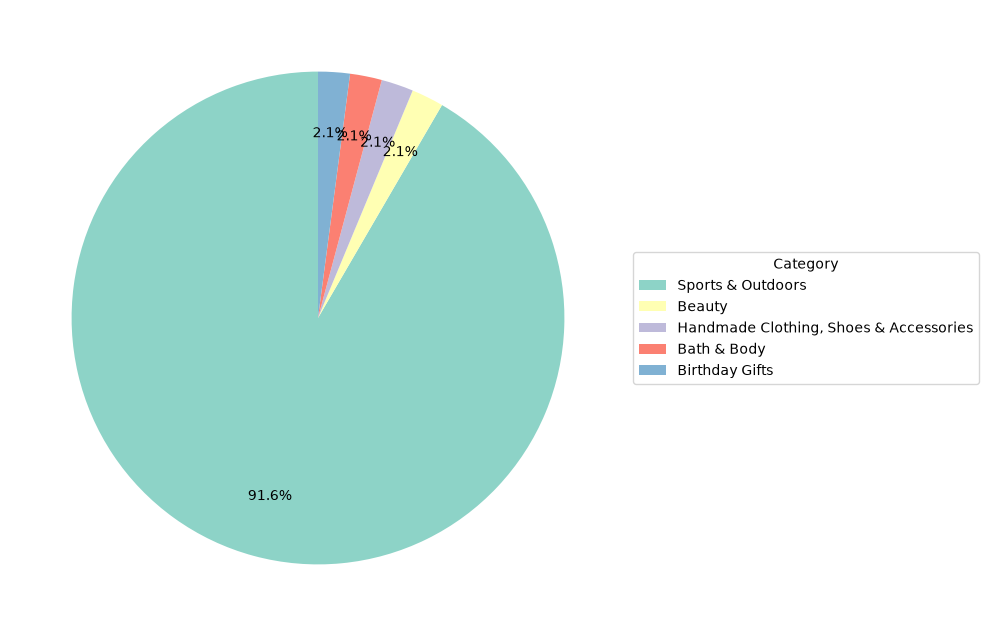

In [31]:
fig, ax = plt.subplots(figsize=(8, 8))
top_five.plot.pie(
    ax=ax,
    autopct="%1.1f%%",          # percentage on each slice
    startangle=90,
    colors=sns.color_palette("Set3"),
    labels=None,                # remove names from around the pie
    pctdistance=0.75            # move percentages toward the edge of each slice
)
ax.legend(top_five.index, title="Category",
          loc="center left", bbox_to_anchor=(1, 0.5))   # names in a legend on the right
ax.set_ylabel("")

In [ ]:
#2 Part 2: Delving into Product Pricing

In [33]:
#Measures of centrality
mean_price = df['price'].mean()
median_price = df['price'].median()
mode_price = df['price'].mode()[0]

mean_price, median_price, mode_price

(np.float64(89.24380943923661), np.float64(19.09), np.float64(9.99))

In [34]:
#Measures of dispersion
variance_price = df['price'].var()
std_dev_price = df['price'].std()
min_price = df['price'].min()
max_price = df['price'].max()
range_price = max_price - min_price
quantiles_price = df['price'].quantile([0.25, 0.5, 0.75])

variance_price, std_dev_price, min_price, max_price, range_price, quantiles_price

(np.float64(119445.48532254901),
 np.float64(345.60886175349873),
 np.float64(0.0),
 np.float64(100000.0),
 np.float64(100000.0),
 0.25     9.99
 0.50    19.09
 0.75    45.99
 Name: price, dtype: float64)

In [ ]:
#prices are extremely varied, but the variation comes from a small number of very expensive products

In [36]:
df["price"].describe()

count    2.443651e+06
mean     8.924381e+01
std      3.456089e+02
min      0.000000e+00
25%      9.990000e+00
50%      1.909000e+01
75%      4.599000e+01
max      1.000000e+05
Name: price, dtype: float64

In [ ]:
#Indicator of spread: standard deviation far larger than the mean for prices that can’t go below 0, this only happens when a few very high values stretch the distribution.

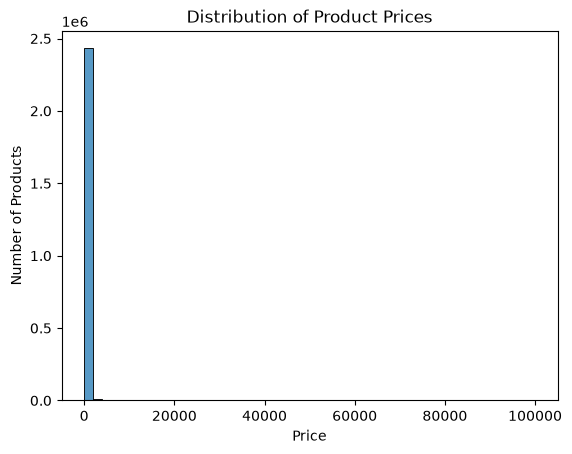

In [37]:
#Visualizations
sns.histplot(df['price'], bins=50)
plt.title("Distribution of Product Prices")
plt.xlabel("Price")
plt.ylabel("Number of Products")
plt.show()

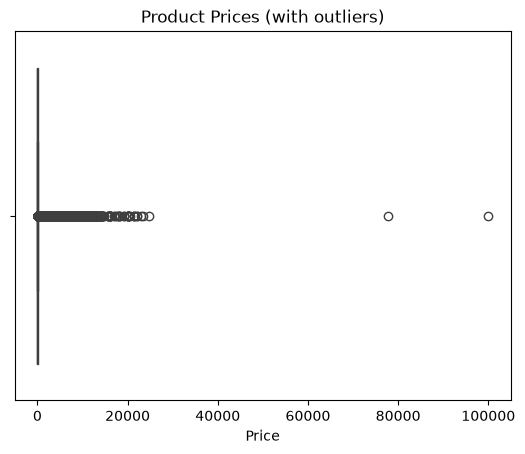

In [39]:
#BoxPlot
sns.boxplot(x=df['price'], showfliers=True)
plt.title("Product Prices (with outliers)")
plt.xlabel("Price")
plt.show()

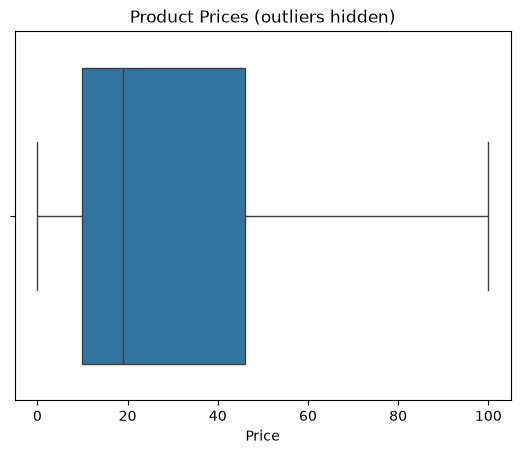

In [40]:
sns.boxplot(x=df['price'], showfliers=False)
plt.title("Product Prices (outliers hidden)")
plt.xlabel("Price")
plt.show()

In [ ]:
#Part 3: Unpacking Product Ratings

In [43]:
#Measures of centrality
mean_price = df['stars'].mean()
median_price = df['stars'].median()
mode_price = df['stars'].mode()[0]
mean_price, median_price, mode_price

(np.float64(2.152836472966066), np.float64(0.0), np.float64(0.0))

In [44]:
df["stars"].tail()

2443646    0.0
2443647    0.0
2443648    0.0
2443649    4.3
2443650    4.5
Name: stars, dtype: float64

In [46]:
df["stars"].describe()

count    2.443651e+06
mean     2.152836e+00
std      2.194865e+00
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      4.400000e+00
max      5.000000e+00
Name: stars, dtype: float64

In [ ]:
#Most products have not been evaluated the median and the mode is zero

In [45]:
variance_rating = df['stars'].var()
std_dev_rating = df['stars'].std()
min_rating = df['stars'].min()
max_rating = df['stars'].max()
range_rating = max_price - min_price
quantiles_rating = df['stars'].quantile([0.25, 0.5, 0.75])

variance_rating, std_dev_rating, min_rating, max_rating, range_rating, quantiles_rating

(np.float64(4.817434029796864),
 np.float64(2.194865378513421),
 np.float64(0.0),
 np.float64(5.0),
 np.float64(100000.0),
 0.25    0.0
 0.50    0.0
 0.75    4.4
 Name: stars, dtype: float64)

In [47]:
skewness_rating = df['stars'].skew()
kurtosis_rating = df['stars'].kurtosis()

skewness_rating, kurtosis_rating

(np.float64(0.08120735761080881), np.float64(-1.9260061280432994))

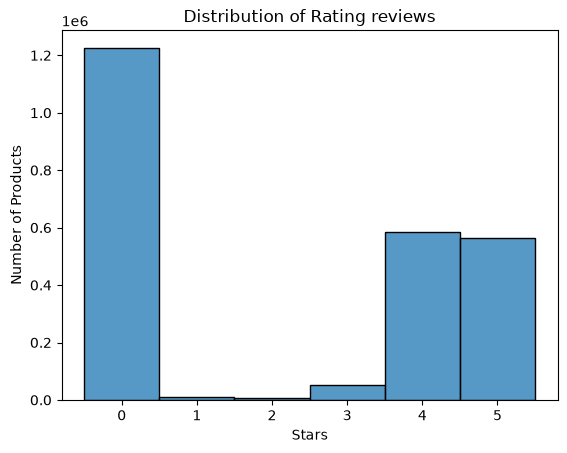

In [48]:
#Visualisation
sns.histplot(df['stars'], discrete=True)
plt.title("Distribution of Rating reviews")
plt.xlabel("Stars")
plt.ylabel("Number of Products")
plt.show()